In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

base = '/content/drive/MyDrive/Research'
data_dir = os.path.join(base, 'X ray Non xray model')

# Real folder names in your Drive
class_folders = {'X_RAY': 'X_RAY', 'NON_XRAY': 'NON_X_RAY'}

for label, folder in class_folders.items():
    files = os.listdir(os.path.join(data_dir, folder))
    print(label, '-> folder:', folder, '| first 5 files:', files[:5])

X_RAY -> folder: X_RAY | first 5 files: ['NormalG0 (203).png', 'NormalG0 (187).png', 'NormalG0 (21).png', 'NormalG0 (185).png', 'NormalG0 (27).png']
NON_XRAY -> folder: NON_X_RAY | first 5 files: ['00507-3846168669.png', '00513-3846168675.png', '00501-3846168663.png', '00535-3846168697.png', '00526-3846168688.png']


X_RAY: 1402 files total, 1402 images
   by extension: {'.png': 1155, '.jpg': 247}
NON_XRAY: 1225 files total, 1225 images
   by extension: {'.png': 320, '.jpeg': 403, '.jpg': 502}


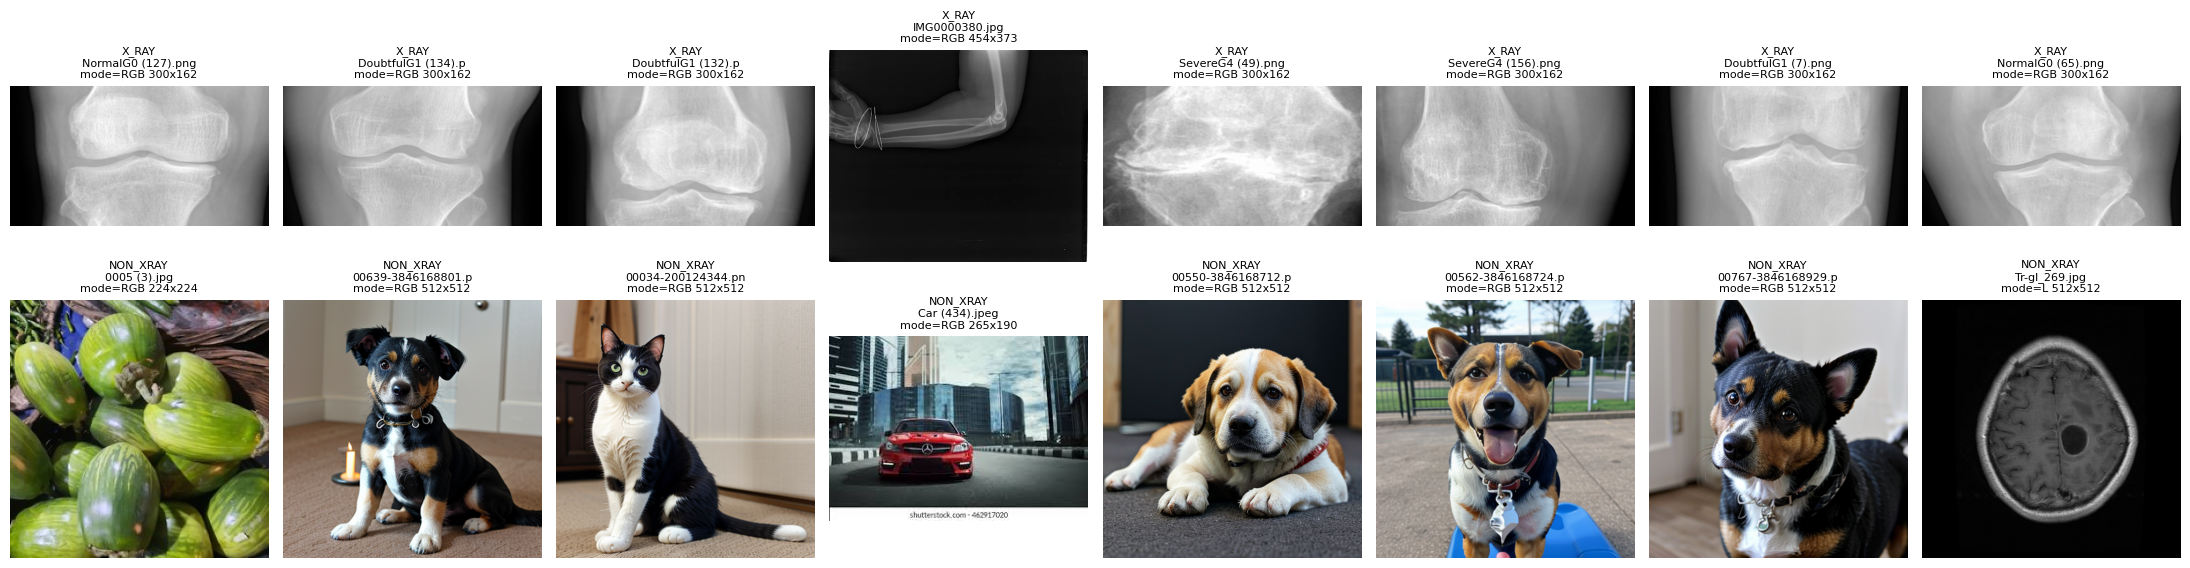

In [ ]:
import os, random
from collections import Counter
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

data_dir = '/content/drive/MyDrive/Research/X ray Non xray model'
class_folders = {'X_RAY': 'X_RAY', 'NON_XRAY': 'NON_X_RAY'}
image_exts = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

# 1) Count files per class, grouped by file extension
all_files = {}
for label, folder in class_folders.items():
    names = os.listdir(os.path.join(data_dir, folder))
    exts = Counter(os.path.splitext(n)[1].lower() for n in names)
    images = [n for n in names if os.path.splitext(n)[1].lower() in image_exts]
    others = [n for n in names if os.path.splitext(n)[1].lower() not in image_exts]
    all_files[label] = images
    print(f'{label}: {len(names)} files total, {len(images)} images')
    print('   by extension:', dict(exts))
    if others:
        print('   NOT images (first 10):', others[:10])

# 2) Helper to display any image safely, including 16-bit X-rays
def load_for_display(path):
    img = Image.open(path)
    mode = img.mode
    arr = np.array(img).astype(np.float32)
    if arr.ndim == 3 and arr.shape[2] == 4:      # drop transparency channel
        arr = arr[:, :, :3]
    arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-6)   # scale to 0-1
    return arr, mode, img.size

# 3) Show 8 random samples from each class
random.seed(42)
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for row, (label, folder) in enumerate(class_folders.items()):
    for col, name in enumerate(random.sample(all_files[label], 8)):
        arr, mode, size = load_for_display(os.path.join(data_dir, folder, name))
        ax = axes[row, col]
        ax.imshow(arr, cmap='gray' if arr.ndim == 2 else None)
        ax.set_title(f'{label}\n{name[:18]}\nmode={mode} {size[0]}x{size[1]}', fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import os, re
from collections import Counter
from PIL import Image

data_dir = '/content/drive/MyDrive/Research/X ray Non xray model'
class_folders = {'X_RAY': 'X_RAY', 'NON_XRAY': 'NON_X_RAY'}

def name_pattern(name):
    stem = os.path.splitext(name)[0]
    stem = re.sub(r'\s*\(\d+\)', '', stem)   # remove " (123)"
    return re.sub(r'\d+', '#', stem)          # replace numbers with #

for label, folder in class_folders.items():
    names = os.listdir(os.path.join(data_dir, folder))
    patterns, sizes, modes = Counter(), Counter(), Counter()
    for n in names:
        patterns[name_pattern(n)] += 1
        with Image.open(os.path.join(data_dir, folder, n)) as im:
            sizes[f'{im.size[0]}x{im.size[1]}'] += 1
            modes[im.mode] += 1
    print(f'\n===== {label} ({len(names)} images) =====')
    print('Filename patterns (top 10):', patterns.most_common(10))
    print('Image sizes (top 8):', sizes.most_common(8))
    print('Image modes:', dict(modes))


===== X_RAY (1402 images) =====
Filename patterns (top 10): [('DoubtfulG#', 252), ('IMG#', 242), ('NormalG#', 208), ('SevereG#', 206), ('H#', 137), ('#_#_#_WRI-R#_M#', 92), ('#_#_#_WRI-L#_M#', 79), ('#_#_#_WRI-R#_F#', 63), ('H# - #', 57), ('#_#_#_WRI-L#_F#', 46)]
Image sizes (top 8): [('300x162', 666), ('373x454', 105), ('454x373', 74), ('2304x2880', 59), ('2880x2304', 3), ('320x453', 2), ('554x755', 2), ('301x401', 2)]
Image modes: {'RGB': 831, 'I;16': 289, 'L': 73, 'RGBA': 209}

===== NON_XRAY (1225 images) =====
Filename patterns (top 10): [('#-#', 320), ('Tr-gl_#', 308), ('Car', 231), ('Bike', 168), ('#', 156), ('#a', 3), ('#AcnePittedScars#', 1), ('#AcnePittedScars', 1), ('#Acne#', 1), ('#-s#.#-B#-f#-#-#', 1)]
Image sizes (top 8): [('512x512', 628), ('224x224', 156), ('275x183', 91), ('300x168', 55), ('100x100', 43), ('720x1280', 34), ('259x194', 32), ('311x162', 13)]
Image modes: {'RGB': 965, 'L': 260}


In [ ]:
!pip install -q medmnist

import os, random
import numpy as np
from PIL import Image
from medmnist import OrganAMNIST, BreastMNIST

out_dir = '/content/drive/MyDrive/Research/outputs/medmnist_review'
random.seed(42)

for DatasetClass, sub in [(OrganAMNIST, 'CT_OrganAMNIST'), (BreastMNIST, 'US_BreastMNIST')]:
    ds = DatasetClass(split='train', download=True, size=224, root='/content')  # download into Colab, not Drive
    picks = random.sample(range(len(ds.imgs)), 300)
    folder = os.path.join(out_dir, sub)
    os.makedirs(folder, exist_ok=True)
    for i in picks:
        Image.fromarray(ds.imgs[i]).save(os.path.join(folder, f'{sub}_{i:05d}.png'))
    print(sub, '-> saved', len(picks), 'images to', folder)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.9 MB/s eta 0:00:00


100%|██████████| 1.80G/1.80G [08:13<00:00, 3.66MB/s]


CT_OrganAMNIST -> saved 300 images to /content/drive/MyDrive/Research/outputs/medmnist_review/CT_OrganAMNIST


100%|██████████| 30.9M/30.9M [00:26<00:00, 1.15MB/s]


US_BreastMNIST -> saved 300 images to /content/drive/MyDrive/Research/outputs/medmnist_review/US_BreastMNIST


In [ ]:
import os, re
import pandas as pd
from PIL import Image

research = '/content/drive/MyDrive/Research'
sources = [
    # (folder path, label)
    (f'{research}/X ray Non xray model/X_RAY', 'X_RAY'),
    (f'{research}/X ray Non xray model/NON_X_RAY', 'NON_XRAY'),
    (f'{research}/outputs/medmnist_review/CT_OrganAMNIST', 'NON_XRAY'),
    (f'{research}/outputs/medmnist_review/US_BreastMNIST', 'NON_XRAY'),
]

def source_and_group(name, label, folder):
    stem = os.path.splitext(name)[0]
    if 'CT_OrganAMNIST' in folder:
        return 'ct_organamnist', stem
    if 'US_BreastMNIST' in folder:
        return 'us_breastmnist', stem
    if label == 'X_RAY':
        if 'WRI' in stem:                                   # GRAZPEDWRI-DX: first number = patient
            return 'grazpedwri', 'graz_' + stem.split('_')[0]
        m = re.match(r'^[Hh](\d*)', stem)
        if m or stem.lower().startswith('capture'):          # hospital: H1 and "H1 - 2" = same group
            return 'hospital', 'hospital_H' + (m.group(1) if m and m.group(1) else stem)
        if re.match(r'^[A-Za-z]+G\d', stem):                 # NormalG0, DoubtfulG1, SevereG4 ...
            return 'knee_kaggle', stem
        if stem.upper().startswith('IMG'):
            return 'unknown_IMG', stem
        return 'other_xray', stem
    else:
        if re.match(r'^\d+-\d+$', stem):
            return 'animals_512_unknown', stem
        if stem.startswith('Tr-'):
            return 'brain_mri_kaggle', stem
        if stem.startswith(('Car', 'Bike')):
            return 'vehicles_unknown', stem
        if re.match(r'^\d+\s*(\(\d+\))?$', stem):
            return 'vegetables_unknown', stem
        return 'other_nonxray', stem

rows = []
for folder, label in sources:
    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        src, group = source_and_group(name, label, folder)
        try:
            with Image.open(path) as im:
                w, h, mode, ok = im.size[0], im.size[1], im.mode, True
        except Exception as e:
            w, h, mode, ok = None, None, None, False
        rows.append(dict(path=path, filename=name, label=label, source=src,
                         group_id=group, width=w, height=h, mode=mode, readable=ok))

df = pd.DataFrame(rows)
os.makedirs(f'{research}/outputs', exist_ok=True)
df.to_csv(f'{research}/outputs/manifest.csv', index=False)

print('Total images:', len(df))
print('Unreadable files:', (~df.readable).sum())
print('\nImages per label and source:')
print(df.groupby(['label', 'source']).size().to_string())

Total images: 3227
Unreadable files: 0

Images per label and source:
label     source             
NON_XRAY  animals_512_unknown    320
          brain_mri_kaggle       308
          ct_organamnist         300
          other_nonxray           42
          us_breastmnist         300
          vegetables_unknown     156
          vehicles_unknown       399
X_RAY     grazpedwri             280
          hospital               209
          knee_kaggle            908
          other_xray               5


In [2]:
import os, re, hashlib, random
import pandas as pd
from PIL import Image

research = '/content/drive/MyDrive/Research'
sources = [
    (f'{research}/X ray Non xray model/X_RAY', 'X_RAY'),
    (f'{research}/X ray Non xray model/NON_X_RAY', 'NON_XRAY'),
    (f'{research}/outputs/medmnist_review/CT_OrganAMNIST', 'NON_XRAY'),
    (f'{research}/outputs/medmnist_review/US_BreastMNIST', 'NON_XRAY'),
]

def source_and_group(name, label, folder):
    stem = os.path.splitext(name)[0]
    if 'CT_OrganAMNIST' in folder: return 'ct_organamnist', stem
    if 'US_BreastMNIST' in folder: return 'us_breastmnist', stem
    if label == 'X_RAY':
        if 'WRI' in stem:  return 'grazpedwri', 'graz_' + stem.split('_')[0]
        if stem.upper().startswith('IMG'): return 'unknown_IMG', stem
        if re.match(r'^(Normal|Doubtful|Minimal|Moderate|Severe)G\d', stem, re.I):
            return 'knee_kaggle', stem
        m = re.match(r'^[Hh](\d*)', stem)
        if m or stem.lower().startswith('capture'):
            return 'hospital', 'hospital_H' + (m.group(1) if m and m.group(1) else stem)
        return 'other_xray', stem
    if re.match(r'^\d+-\d+$', stem):            return 'animals_512_unknown', stem
    if stem.startswith('Tr-'):                   return 'brain_mri_kaggle', stem
    if stem.startswith(('Car', 'Bike')):         return 'vehicles_unknown', stem
    if re.match(r'^\d+\s*(\(\d+\))?$', stem):    return 'vegetables_unknown', stem
    return 'other_nonxray', stem

rows = []
for folder, label in sources:
    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        src, group = source_and_group(name, label, folder)
        with open(path, 'rb') as f:
            md5 = hashlib.md5(f.read()).hexdigest()
        try:
            with Image.open(path) as im:
                w, h, mode, ok = im.size[0], im.size[1], im.mode, True
        except Exception:
            w, h, mode, ok = None, None, None, False
        rows.append(dict(path=path, filename=name, label=label, source=src, group_id=group,
                         md5=md5, width=w, height=h, mode=mode, readable=ok))
df = pd.DataFrame(rows)

conflicts = df.groupby('md5').label.nunique()
conflicts = conflicts[conflicts > 1].index
print('Same image in BOTH classes (label conflict):', len(conflicts))
if len(conflicts):
    print(df[df.md5.isin(conflicts)][['filename', 'label', 'source']].to_string())

df['group_id'] = df.groupby('md5').group_id.transform('first')
df['is_duplicate'] = df.duplicated('md5', keep='first')
print('Exact duplicate copies (not used, NOT deleted):', df.is_duplicate.sum())

use = df[df.readable & ~df.is_duplicate & ~df.md5.isin(conflicts)].copy()
random.seed(42)
split_of = {}
for label in ['X_RAY', 'NON_XRAY']:
    groups = sorted(use[use.label == label].group_id.unique())
    random.shuffle(groups)
    n = len(groups)
    for i, g in enumerate(groups):
        split_of[g] = 'train' if i < 0.70 * n else ('val' if i < 0.85 * n else 'test')
use['split'] = use.group_id.map(split_of)

df = df.merge(use[['path', 'split']], on='path', how='left')
df['split'] = df['split'].fillna('not_used')
df.to_csv(f'{research}/outputs/manifest_split.csv', index=False)

print('\nImages per split and class:')
print(pd.crosstab(df.split, df.label, margins=True).to_string())
print('\nImages per source and split:')
print(pd.crosstab([df.label, df.source], df.split).to_string())

Same image in BOTH classes (label conflict): 0
Exact duplicate copies (not used, NOT deleted): 6

Images per split and class:
label     NON_XRAY  X_RAY   All
split                          
not_used         1      5     6
test           273    269   542
train         1277   1155  2432
val            274    255   529
All           1825   1684  3509

Images per source and split:
split                         not_used  test  train  val
label    source                                         
NON_XRAY animals_512_unknown         0    47    231   42
         brain_mri_kaggle            0    50    206   52
         ct_organamnist              0    50    198   52
         other_nonxray               1     4     31    6
         us_breastmnist              0    48    211   41
         vegetables_unknown          0    26    101   29
         vehicles_unknown            0    48    299   52
X_RAY    grazpedwri                  0    53    180   47
         hospital                    2    68    23